# 05 Fidelity: how closely does synthetic data match real training data?

**Purpose:** measure the statistical fidelity of every synthetic training set produced in `04_generators.ipynb`, using one method for all of them so results can be compared.

**Data rule:** each synthetic set is compared against **real `train.csv`** (with its genuine NaNs). **The test set is never loaded in this notebook.** Nothing is trained here.

**Experiments**

| Section | Strategy | Variant | Synthetic files compared |
|---|---|---|---|
| 1 | `random` | baseline, no target column | `{ctgan,tvae}_random_restored.csv` |
| 2 | `random` | target as generator column, unbalanced | `{ctgan,tvae}_random_target_restored.csv` |
| 3 | `from_column` | target as generator column, unbalanced | `{ctgan,tvae}_from_column_target_restored.csv` |
| 4 | all | side-by-side comparison | in memory |

**Metrics**
- **Column Shapes:** SDV quality report. The label is declared categorical where it exists.
- **Column Pair Trends:** mean `CorrelationSimilarity` over the six feature pairs, computed directly, because the SDV report returns `NaN` for this property in SDV 2.0.0 / SDMetrics 0.32.0 (evidence: `00_api_checks.ipynb`, section G). Each pair uses rows where both values are present. The label is excluded, because correlation is not defined for a categorical column.
- **Overall quality:** mean of Column Shapes and Pair Trends.
- **Missing-value similarity:** `MissingValueSimilarity` per feature, plus the raw difference in missing rate (percentage points).

**Comparability notes**
- Column Shapes averages **four** columns in the baseline and **five** in the target variants (the label scores near 1 and lifts the average mechanically). Compare baseline against target variants with care. The two target variants (sections 2 and 3) are like-for-like.
- Pair Trends covers the same four features everywhere.
- The manual pair-trends score follows the same idea as SDV's report but is not guaranteed identical to it, so the paper's values are for orientation only.

**Reproducibility check:** the saved numbers from earlier runs are listed in the setup cell, and each section prints whether the recomputed values match them.

**Outputs:** `reports/synthetic_quality_random_baseline.json`, `reports/synthetic_quality_random_target.json`, `reports/synthetic_quality_from_column_target.json`, `reports/fidelity_summary.json`.

In [20]:

# ============================================================
# NOTEBOOK 05 — MULTI-SEED FIDELITY EVALUATION
# ============================================================

import json
from datetime import datetime, timezone
from itertools import combinations
from pathlib import Path

import pandas as pd
import sdmetrics
import sdv

from sdmetrics.column_pairs import CorrelationSimilarity
from sdmetrics.single_column import MissingValueSimilarity
from sdv.evaluation import evaluate_quality
from sdv.metadata import Metadata


# ============================================================
# 1. EXPERIMENT SETTINGS
# ============================================================

FEATURES = [
    "nevents",
    "ndays_act",
    "ncontent",
    "nforum_posts"
]

GAP_COLS = [
    "nevents",
    "ndays_act",
    "nforum_posts"
]

TARGET = "Engagement_Level"
TABLE = "students"

GENERATORS = ("ctgan", "tvae")

SEEDS = [42, 123, 2026, 3407]

STRATEGIES = ("random", "from_column")


# Original seed-42 reproducibility reference values.
EXPECTED = {
    "random_baseline": {
        "ctgan": {
            "column_shapes": 0.8942,
            "pair_trends": 0.9394,
            "overall_quality": 0.9168
        },
        "tvae": {
            "column_shapes": 0.8643,
            "pair_trends": 0.9338,
            "overall_quality": 0.8990
        }
    },

    "random_target": {
        "ctgan": {
            "column_shapes": 0.9343,
            "pair_trends": 0.9624,
            "overall_quality": 0.9483
        },
        "tvae": {
            "column_shapes": 0.9141,
            "pair_trends": 0.9273,
            "overall_quality": 0.9207
        }
    },

    "from_column_target": {
        "ctgan": {
            "column_shapes": 0.9433,
            "pair_trends": 0.9587,
            "overall_quality": 0.9510
        },
        "tvae": {
            "column_shapes": 0.9297,
            "pair_trends": 0.9567,
            "overall_quality": 0.9432
        }
    }
}


# ============================================================
# 2. PROJECT PATHS
# ============================================================

def find_project_root(start=None):
    """Find the project root using configs/base.yaml."""

    start = Path(start or Path.cwd()).resolve()

    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder

    raise FileNotFoundError(
        f"Could not find configs/base.yaml above {start}"
    )


PROJECT_ROOT = find_project_root()

DATA_DIR = PROJECT_ROOT / "data" / "processed"

GEN_DIR = PROJECT_ROOT / "artifacts" / "generators"

ROBUSTNESS_DIR = PROJECT_ROOT / "artifacts" / "robustness"

REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 3. LOAD REAL TRAINING DATA
# ============================================================

REAL_FULL = pd.read_csv(
    DATA_DIR / "train.csv"
)[FEATURES + [TARGET]]

if REAL_FULL.shape[0] != 21328:
    raise ValueError(
        f"Unexpected real training shape: {REAL_FULL.shape}"
    )

print("Project root:", PROJECT_ROOT)
print("Real training shape:", REAL_FULL.shape)

print(
    "Real missingness (%):",
    (REAL_FULL[FEATURES].isna().mean() * 100).round(2).to_dict()
)


# ============================================================
# 4. BUILD SDV METADATA
# ============================================================

def build_metadata(df: pd.DataFrame) -> Metadata:
    """Detect metadata and mark the target as categorical."""

    metadata = Metadata.detect_from_dataframes(
        {TABLE: df}
    )

    if TARGET in df.columns:
        metadata.update_column(
            column_name=TARGET,
            table_name=TABLE,
            sdtype="categorical"
        )

    return metadata


# ============================================================
# 5. FIDELITY METRICS
# ============================================================

def column_shapes(
    real: pd.DataFrame,
    fake: pd.DataFrame,
    metadata
) -> float:
    """Calculate SDV Column Shapes quality."""

    report = evaluate_quality(
        {TABLE: real},
        {TABLE: fake},
        metadata,
        verbose=False
    )

    properties = report.get_properties()

    score = properties.loc[
        properties["Property"] == "Column Shapes",
        "Score"
    ].iloc[0]

    return float(score)


def pair_trends(
    real: pd.DataFrame,
    fake: pd.DataFrame
) -> tuple[float, dict]:
    """
    Calculate mean CorrelationSimilarity across
    the six feature pairs using pairwise-complete rows.
    """

    scores = {}

    for a, b in combinations(FEATURES, 2):

        pair = [a, b]

        real_pair = real[pair].dropna()
        fake_pair = fake[pair].dropna()

        if len(real_pair) < 2 or len(fake_pair) < 2:
            raise ValueError(
                f"Insufficient complete rows for pair {a}, {b}"
            )

        score = CorrelationSimilarity.compute(
            real_pair,
            fake_pair
        )

        if pd.isna(score):
            raise ValueError(
                f"Pair Trends returned NaN for {a}, {b}"
            )

        scores[f"{a}|{b}"] = float(score)

    return (
        sum(scores.values()) / len(scores),
        scores
    )


def evaluate_generator(
    real: pd.DataFrame,
    fake: pd.DataFrame,
    metadata
) -> dict:
    """Calculate all fidelity metrics for one synthetic dataset."""

    shapes = column_shapes(real, fake, metadata)

    trends, per_pair = pair_trends(real, fake)

    result = {
        "column_shapes": shapes,

        "pair_trends": trends,

        "overall_quality": (shapes + trends) / 2,

        "pair_trends_per_pair": per_pair,

        "missing_value_similarity": {
            column: float(
                MissingValueSimilarity.compute(
                    real[column],
                    fake[column]
                )
            )
            for column in FEATURES
        },

        "missing_rate_difference_points": {
            column: round(
                float(
                    (
                        fake[column].isna().mean()
                        - real[column].isna().mean()
                    ) * 100
                ),
                2
            )
            for column in FEATURES
        }
    }

    if TARGET in fake.columns:

        share = (
            fake[TARGET]
            .value_counts(normalize=True)
            .sort_index()
            .round(4)
            .to_dict()
        )

        result["class_share_synthetic"] = {
            str(k): float(v)
            for k, v in share.items()
        }

    return result


# ============================================================
# 6. FIND SYNTHETIC DATASET FOR EACH SEED
# ============================================================

def get_synthetic_path(
    seed: int,
    generator: str,
    strategy: str
) -> Path:
    """
    Seed 42 uses the original generator folder.
    Additional seeds use their separate robustness folders.
    """

    tag = f"{generator}_{strategy}_target_restored.csv"

    if seed == 42:
        return GEN_DIR / tag

    return (
        ROBUSTNESS_DIR
        / f"seed_{seed}"
        / tag
    )


# ============================================================
# 7. EVALUATE ONE SEED AND ONE STRATEGY
# ============================================================

def evaluate_seed_strategy(
    seed: int,
    strategy: str
) -> dict:
    """Evaluate CTGAN and TVAE for one seed and strategy."""

    if strategy not in STRATEGIES:
        raise ValueError(
            f"Unsupported strategy: {strategy}"
        )

    cols = FEATURES + [TARGET]

    real = REAL_FULL[cols]

    metadata = build_metadata(real)

    results = {
        "seed": seed,
        "strategy": strategy,
        "compared_against": "real train with genuine NaNs",
        "sdv_version": sdv.__version__,
        "sdmetrics_version": sdmetrics.__version__,
        "generators": {}
    }

    for generator in GENERATORS:

        path = get_synthetic_path(
            seed,
            generator,
            strategy
        )

        print(
            f"\nEvaluating {generator.upper()} | "
            f"Seed {seed} | {strategy}"
        )

        if not path.exists():
            raise FileNotFoundError(
                f"Synthetic dataset not found: {path}"
            )

        fake = pd.read_csv(path)

        missing_columns = set(cols) - set(fake.columns)

        if missing_columns:
            raise ValueError(
                f"{path.name} is missing columns: {missing_columns}"
            )

        fake = fake[cols]

        if fake.shape[0] != len(real):
            raise ValueError(
                f"Unexpected synthetic row count in {path.name}: "
                f"{len(fake)}"
            )

        res = evaluate_generator(
            real,
            fake,
            metadata
        )

        results["generators"][generator] = res

        print(
            f"Column Shapes: {res['column_shapes']:.4f}"
        )

        print(
            f"Pair Trends: {res['pair_trends']:.4f}"
        )

        print(
            f"Overall Quality: {res['overall_quality']:.4f}"
        )

        print(
            "Missing similarity:",
            {
                k: round(v, 4)
                for k, v in res["missing_value_similarity"].items()
            }
        )

        print(
            "Missing-rate difference (percentage points):",
            res["missing_rate_difference_points"]
        )

        print(
            "Class distribution:",
            res.get("class_share_synthetic", "Not available")
        )

    output_path = REPORT_DIR / (
        f"fidelity_seed_{seed}_{strategy}_target.json"
    )

    output_path.write_text(
        json.dumps(results, indent=2),
        encoding="utf-8"
    )

    print("\nSaved:", output_path.name)

    return results


# ============================================================
# 8. ORIGINAL SINGLE-SEED BASELINE EVALUATION
# ============================================================

def run_variant(
    key: str,
    strategy: str,
    variant: str,
    file_pattern: str,
    with_target: bool
) -> dict:
    """
    Preserve the original seed-42 no-target baseline evaluation.
    """

    cols = FEATURES + [TARGET] if with_target else FEATURES

    real = REAL_FULL[cols]

    metadata = build_metadata(real)

    results = {
        "seed": 42,
        "sdv": sdv.__version__,
        "sdmetrics": sdmetrics.__version__,
        "strategy": strategy,
        "variant": variant,
        "compared_against": "real train with genuine NaNs",
        "generators": {}
    }

    for name in GENERATORS:

        path = GEN_DIR / file_pattern.format(name=name)

        if not path.exists():
            raise FileNotFoundError(
                f"Original seed-42 file not found: {path}"
            )

        fake = pd.read_csv(path)[cols]

        res = evaluate_generator(
            real,
            fake,
            metadata
        )

        results["generators"][name] = res

        print(
            f"{name.upper()} | {strategy} | {variant}"
        )

        print(
            f"Column Shapes: {res['column_shapes']:.4f}"
        )

        print(
            f"Pair Trends: {res['pair_trends']:.4f}"
        )

        print(
            f"Overall Quality: {res['overall_quality']:.4f}"
        )

        expected = EXPECTED.get(key, {}).get(name)

        if expected:

            matches = all(
                abs(res[metric] - value) < 5e-4
                for metric, value in expected.items()
            )

            print(
                "Seed-42 reproducibility:",
                "MATCH" if matches else "DIFFERS"
            )

        print()

    output_path = REPORT_DIR / f"synthetic_quality_{key}.json"

    output_path.write_text(
        json.dumps(results, indent=2),
        encoding="utf-8"
    )

    print("Saved:", output_path.name)

    return results


# ============================================================
# 9. RESULTS CONTAINERS
# ============================================================

all_results = {}

multi_seed_results = {}

print("\nSDV version:", sdv.__version__)
print("SDMetrics version:", sdmetrics.__version__)
print("Seeds:", SEEDS)
print("Generators:", GENERATORS)
print("Strategies:", STRATEGIES)

print("\nNotebook 05 setup completed.")


Project root: D:\student_engagement_twin
Real training shape: (21328, 5)
Real missingness (%): {'nevents': 17.08, 'ndays_act': 10.53, 'ncontent': 0.0, 'nforum_posts': 68.11}

SDV version: 2.0.0
SDMetrics version: 0.32.0
Seeds: [42, 123, 2026, 3407]
Generators: ('ctgan', 'tvae')
Strategies: ('random', 'from_column')

Notebook 05 setup completed.


Configuration and constants

In [2]:
FEATURES = [
    "nevents",
    "ndays_act",
    "ncontent",
    "nforum_posts",
]

GAP_COLS = [
    "nevents",
    "ndays_act",
    "nforum_posts",
]

TARGET = "Engagement_Level"
TABLE = "students"

GENERATORS = ("ctgan", "tvae")

EXPECTED = {
    "random_baseline": {
        "ctgan": {
            "column_shapes": 0.8942,
            "pair_trends": 0.9394,
            "overall_quality": 0.9168,
        },
        "tvae": {
            "column_shapes": 0.8643,
            "pair_trends": 0.9338,
            "overall_quality": 0.8990,
        },
    },
    "random_target": {
        "ctgan": {
            "column_shapes": 0.9343,
            "pair_trends": 0.9624,
            "overall_quality": 0.9483,
        },
        "tvae": {
            "column_shapes": 0.9141,
            "pair_trends": 0.9273,
            "overall_quality": 0.9207,
        },
    },
}

Project paths and data loading

In [3]:
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()

    for folder in [start, *start.parents]:
        config_file = folder / "configs" / "base.yaml"

        if config_file.exists():
            return folder

    raise FileNotFoundError(
        "Could not locate project root. "
        "Expected configs/base.yaml in the project directory."
    )


ROOT = find_project_root()

GEN_DIR = ROOT / "artifacts" / "generators"
REPORT_DIR = ROOT / "reports"

TRAIN_PATH = ROOT / "data" / "processed" / "train.csv"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

if not TRAIN_PATH.exists():
    raise FileNotFoundError(f"Training data not found: {TRAIN_PATH}")

if not GEN_DIR.exists():
    raise FileNotFoundError(f"Generator directory not found: {GEN_DIR}")

REAL_FULL = pd.read_csv(TRAIN_PATH)

required_columns = FEATURES + [TARGET]

missing_columns = [
    col for col in required_columns
    if col not in REAL_FULL.columns
]

if missing_columns:
    raise ValueError(
        f"Training data is missing required columns: {missing_columns}"
    )

REAL_FULL = REAL_FULL[required_columns].copy()

print("Project root:", ROOT)
print("Generator directory:", GEN_DIR)
print("Report directory:", REPORT_DIR)
print("Real training data shape:", REAL_FULL.shape)

print("\nMissing values in real training data:")
display(REAL_FULL.isna().sum().to_frame("Missing values"))

Project root: D:\student_engagement_twin
Generator directory: D:\student_engagement_twin\artifacts\generators
Report directory: D:\student_engagement_twin\reports
Real training data shape: (21328, 5)

Missing values in real training data:


,Missing values
nevents,3643
ndays_act,2246
ncontent,0
nforum_posts,14526
Engagement_Level,0


Metadata creation

In [4]:
def build_metadata(df):
    """
    Detect SDV metadata from a DataFrame.

    Engagement_Level is explicitly treated as categorical,
    even though it is represented using numeric labels 0 and 1.
    """

    if not isinstance(df, pd.DataFrame):
        raise TypeError("Input must be a pandas DataFrame.")

    if df.empty:
        raise ValueError("Cannot build metadata from an empty DataFrame.")

    metadata = Metadata.detect_from_dataframes({
        TABLE: df
    })

    if TARGET in df.columns:
        metadata.update_column(
            column_name=TARGET,
            table_name=TABLE,
            sdtype="categorical",
        )

    return metadata

Generator evaluation function

In [5]:
def evaluate_generator(real, fake, metadata):
    """
    Evaluate synthetic data against real training data.

    Metrics:
    1. Column Shapes
    2. Column Pair Trends
    3. Overall Quality
    4. Missing Value Similarity
    5. Missing Rate Difference
    6. Synthetic class distribution, when target is present
    """

    if not isinstance(real, pd.DataFrame):
        raise TypeError("Real data must be a pandas DataFrame.")

    if not isinstance(fake, pd.DataFrame):
        raise TypeError("Synthetic data must be a pandas DataFrame.")

    if real.empty or fake.empty:
        raise ValueError("Real and synthetic datasets must not be empty.")

    if list(real.columns) != list(fake.columns):
        raise ValueError(
            "Real and synthetic datasets must have identical columns "
            "in the same order."
        )

    # 1. Column Shapes
    shapes = column_shapes(
        real,
        fake,
        metadata,
    )

    # 2. Column Pair Trends
    # Target is excluded: only the four engagement features are compared.
    trends, per_pair = pair_trends(
        real,
        fake,
        FEATURES,
    )

    # 3. Missing Value Similarity
    missing_scores = missing_similarity(
        real,
        fake,
        FEATURES,
    )

    # 4. Overall Quality
    quality = overall_quality(
        shapes,
        trends,
    )

    # 5. Missing rate differences in percentage points
    missing_rate_difference = {
        col: round(
            float(
                (fake[col].isna().mean() - real[col].isna().mean()) * 100
            ),
            2,
        )
        for col in FEATURES
    }

    result = {
        "column_shapes": shapes,
        "pair_trends": trends,
        "overall_quality": quality,
        "pair_trends_per_pair": per_pair,
        "missing_value_similarity": missing_scores,
        "missing_rate_difference_points": missing_rate_difference,
    }

    # 6. Class distribution, when target is included
    if TARGET in fake.columns:
        class_share = (
            fake[TARGET]
            .value_counts(normalize=True)
            .sort_index()
            .to_dict()
        )

        result["class_share_synthetic"] = {
            str(key): round(float(value), 4)
            for key, value in class_share.items()
        }

    return result

Save evaluation reports

In [6]:
def save_report(report, filename):
    """
    Save an evaluation report as JSON.
    """

    output_path = REPORT_DIR / filename

    with open(output_path, "w", encoding="utf-8") as file:
        json.dump(
            report,
            file,
            indent=4,
            allow_nan=False,
        )

    print(f"Report saved: {output_path}")

    return output_path

Expected result comparison

In [7]:
def compare_with_expected(variant, generator, result):
    """
    Compare reproduced results against the reference values
    recorded from the paper/reproduction experiment.

    A tolerance of 0.0005 is used for the recorded four-decimal scores.
    """

    if variant not in EXPECTED:
        return

    if generator not in EXPECTED[variant]:
        return

    expected = EXPECTED[variant][generator]

    print("\nReference comparison:")

    for metric in [
        "column_shapes",
        "pair_trends",
        "overall_quality",
    ]:
        actual_value = result[metric]
        expected_value = expected[metric]

        difference = abs(actual_value - expected_value)

        status = (
            "MATCH"
            if difference < 0.0005
            else "DIFFERENCE"
        )

        print(
            f"{metric}: "
            f"Expected={expected_value:.4f}, "
            f"Actual={actual_value:.4f}, "
            f"Difference={difference:.6f} "
            f"[{status}]"
        )

Experiment 1: Random baseline (without target)

In [21]:
all_results["random_baseline"] = run_variant(
    key="random_baseline",
    strategy="random",
    variant="no-target baseline",
    file_pattern="{name}_random_restored.csv",
    with_target=False
)

CTGAN | random | no-target baseline
Column Shapes: 0.8942
Pair Trends: 0.9394
Overall Quality: 0.9168
Seed-42 reproducibility: MATCH

TVAE | random | no-target baseline
Column Shapes: 0.8643
Pair Trends: 0.9338
Overall Quality: 0.8990
Seed-42 reproducibility: MATCH

Saved: synthetic_quality_random_baseline.json


Experiment 2: Random missingness with target

In [22]:
# ============================================================
# RANDOM STRATEGY — TARGET VARIANT
# ============================================================

for seed in SEEDS:

    print("\n" + "=" * 65)
    print(f"RANDOM STRATEGY | SEED {seed}")
    print("=" * 65)

    result = evaluate_seed_strategy(
        seed=seed,
        strategy="random"
    )

    multi_seed_results[
        f"random_target_seed_{seed}"
    ] = result


RANDOM STRATEGY | SEED 42

Evaluating CTGAN | Seed 42 | random
Column Shapes: 0.9343
Pair Trends: 0.9624
Overall Quality: 0.9483
Missing similarity: {'nevents': 0.9996, 'ndays_act': 0.9995, 'ncontent': 1.0, 'nforum_posts': 0.9962}
Missing-rate difference (percentage points): {'nevents': 0.04, 'ndays_act': -0.05, 'ncontent': 0.0, 'nforum_posts': 0.38}
Class distribution: {'0': 0.824, '1': 0.176}

Evaluating TVAE | Seed 42 | random
Column Shapes: 0.9141
Pair Trends: 0.9273
Overall Quality: 0.9207
Missing similarity: {'nevents': 0.9996, 'ndays_act': 0.9995, 'ncontent': 1.0, 'nforum_posts': 0.9962}
Missing-rate difference (percentage points): {'nevents': 0.04, 'ndays_act': -0.05, 'ncontent': 0.0, 'nforum_posts': 0.38}
Class distribution: {'0': 0.8435, '1': 0.1565}

Saved: fidelity_seed_42_random_target.json

RANDOM STRATEGY | SEED 123

Evaluating CTGAN | Seed 123 | random
Column Shapes: 0.9197
Pair Trends: 0.9600
Overall Quality: 0.9399
Missing similarity: {'nevents': 0.9996, 'ndays_act':

Experiment 3: From-column missingness with target

In [23]:
# ============================================================
# FROM_COLUMN STRATEGY — TARGET VARIANT
# ============================================================

for seed in SEEDS:

    print("\n" + "=" * 65)
    print(f"FROM_COLUMN STRATEGY | SEED {seed}")
    print("=" * 65)

    result = evaluate_seed_strategy(
        seed=seed,
        strategy="from_column"
    )

    multi_seed_results[
        f"from_column_target_seed_{seed}"
    ] = result


FROM_COLUMN STRATEGY | SEED 42

Evaluating CTGAN | Seed 42 | from_column
Column Shapes: 0.9433
Pair Trends: 0.9587
Overall Quality: 0.9510
Missing similarity: {'nevents': 0.9129, 'ndays_act': 0.9611, 'ncontent': 1.0, 'nforum_posts': 0.9728}
Missing-rate difference (percentage points): {'nevents': 8.71, 'ndays_act': -3.89, 'ncontent': 0.0, 'nforum_posts': 2.72}
Class distribution: {'0': 0.8352, '1': 0.1648}

Evaluating TVAE | Seed 42 | from_column
Column Shapes: 0.9297
Pair Trends: 0.9567
Overall Quality: 0.9432
Missing similarity: {'nevents': 0.9801, 'ndays_act': 0.8984, 'ncontent': 1.0, 'nforum_posts': 0.9651}
Missing-rate difference (percentage points): {'nevents': -1.99, 'ndays_act': -10.16, 'ncontent': 0.0, 'nforum_posts': -3.49}
Class distribution: {'0': 0.8296, '1': 0.1704}

Saved: fidelity_seed_42_from_column_target.json

FROM_COLUMN STRATEGY | SEED 123

Evaluating CTGAN | Seed 123 | from_column
Column Shapes: 0.9424
Pair Trends: 0.9610
Overall Quality: 0.9517
Missing similarit

Consolidated comparison

In [24]:

# ============================================================
# MULTI-SEED FIDELITY SUMMARY
# ============================================================

# 1. Verify that all 8 seed-strategy combinations were evaluated.

expected_keys = {
    f"{strategy}_target_seed_{seed}"
    for strategy in STRATEGIES
    for seed in SEEDS
}

if set(multi_seed_results.keys()) != expected_keys:
    raise ValueError(
        "Missing or unexpected evaluations.\n"
        f"Expected: {sorted(expected_keys)}\n"
        f"Found: {sorted(multi_seed_results.keys())}"
    )


# 2. Build one row per seed, strategy and generator.

rows = []

for result_key, result in multi_seed_results.items():

    seed = result["seed"]
    strategy = result["strategy"]

    for generator, metrics in result["generators"].items():

        missing_sim = metrics["missing_value_similarity"]

        rows.append({
            "seed": seed,
            "strategy": strategy,
            "generator": generator,

            "column_shapes": metrics["column_shapes"],

            "pair_trends": metrics["pair_trends"],

            "overall_quality": metrics["overall_quality"],

            "missing_sim_mean": sum(
                missing_sim[column]
                for column in GAP_COLS
            ) / len(GAP_COLS),

            "class_1_share": metrics[
                "class_share_synthetic"
            ].get("1")
        })


per_seed_summary = pd.DataFrame(rows)

per_seed_summary = per_seed_summary.sort_values(
    ["strategy", "generator", "seed"]
).reset_index(drop=True)


# 3. Verify the expected number of generator evaluations.

if len(per_seed_summary) != 16:
    raise ValueError(
        f"Expected 16 generator evaluations, found {len(per_seed_summary)}"
    )


# 4. Calculate mean and sample standard deviation across seeds.

METRICS = [
    "column_shapes",
    "pair_trends",
    "overall_quality",
    "missing_sim_mean",
    "class_1_share"
]

aggregate_summary = (
    per_seed_summary
    .groupby(["strategy", "generator"])[METRICS]
    .agg(["mean", "std"])
    .round(4)
)


# 5. Display per-seed results.

print("=" * 75)
print("PER-SEED FIDELITY RESULTS")
print("=" * 75)

display(
    per_seed_summary.round(4)
)


# 6. Display multi-seed mean and standard deviation.

print("\n" + "=" * 75)
print("MULTI-SEED FIDELITY: MEAN ± STANDARD DEVIATION")
print("=" * 75)

display(aggregate_summary)


# 7. Preserve the original no-target baseline separately.

baseline_rows = []

baseline = all_results["random_baseline"]

for generator, metrics in baseline["generators"].items():

    missing_sim = metrics["missing_value_similarity"]

    baseline_rows.append({
        "seed": 42,
        "generator": generator,
        "column_shapes": metrics["column_shapes"],
        "pair_trends": metrics["pair_trends"],
        "overall_quality": metrics["overall_quality"],
        "missing_sim_mean": sum(
            missing_sim[column]
            for column in GAP_COLS
        ) / len(GAP_COLS)
    })

baseline_summary = pd.DataFrame(baseline_rows).round(4)

print("\n" + "=" * 75)
print("ORIGINAL SEED-42 NO-TARGET BASELINE")
print("=" * 75)

display(baseline_summary)


# 8. Save detailed and aggregate reports.

per_seed_summary.to_csv(
    REPORT_DIR / "fidelity_per_seed.csv",
    index=False
)

aggregate_summary.to_csv(
    REPORT_DIR / "fidelity_multi_seed_mean_std.csv"
)

payload = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(
        timespec="seconds"
    ),

    "versions": {
        "sdv": sdv.__version__,
        "sdmetrics": sdmetrics.__version__,
        "pandas": pd.__version__
    },

    "seeds": SEEDS,

    "generators": list(GENERATORS),

    "strategies": list(STRATEGIES),

    "compared_against": (
        "Real training data with genuine NaNs. "
        "Test data was not used."
    ),

    "standard_deviation": (
        "Sample standard deviation across four generator seeds."
    ),

    "per_seed_results": per_seed_summary.to_dict(
        orient="records"
    ),

    "multi_seed_mean_std": {
        str(index): {
            f"{metric}_{stat}": float(value)
            if pd.notna(value) else None
            for (metric, stat), value in row.items()
        }
        for index, row in aggregate_summary.iterrows()
    },

    "original_no_target_baseline_seed_42": (
        baseline_summary.to_dict(orient="records")
    )
}

summary_path = REPORT_DIR / "fidelity_multi_seed_summary.json"

summary_path.write_text(
    json.dumps(payload, indent=2),
    encoding="utf-8"
)

print("\nSaved reports:")
print(" - fidelity_per_seed.csv")
print(" - fidelity_multi_seed_mean_std.csv")
print(" - fidelity_multi_seed_summary.json")

print("\nAll multi-seed fidelity evaluations completed.")


PER-SEED FIDELITY RESULTS


,seed,strategy,generator,column_shapes,pair_trends,overall_quality,missing_sim_mean,class_1_share
0,42,from_column,ctgan,0.9433,0.9587,0.9510,0.9489,0.1648
1,123,from_column,ctgan,0.9424,0.9610,0.9517,0.9650,0.1630
2,2026,from_column,ctgan,0.9348,0.9489,0.9418,0.9517,0.1352
3,3407,from_column,ctgan,0.9319,0.9596,0.9458,0.9688,0.2095
4,42,from_column,tvae,0.9297,0.9567,0.9432,0.9479,0.1704
5,123,from_column,tvae,0.9336,0.9308,0.9322,0.9627,0.1598
6,2026,from_column,tvae,0.9135,0.9056,0.9095,0.9321,0.1918
7,3407,from_column,tvae,0.9282,0.9538,0.9410,0.9880,0.2043
8,42,random,ctgan,0.9343,0.9624,0.9483,0.9985,0.1760
9,123,random,ctgan,0.9197,0.9600,0.9399,0.9985,0.1760



MULTI-SEED FIDELITY: MEAN ± STANDARD DEVIATION


column_shapes         pair_trends          \
                               mean     std        mean     std   
strategy    generator                                             
from_column ctgan            0.9381  0.0056      0.9571  0.0055   
            tvae             0.9263  0.0088      0.9367  0.0238   
random      ctgan            0.9276  0.0060      0.9598  0.0044   
            tvae             0.9077  0.0087      0.9242  0.0065   

                      overall_quality         missing_sim_mean          \
                                 mean     std             mean     std   
strategy    generator                                                    
from_column ctgan              0.9476  0.0047           0.9586  0.0098   
            tvae               0.9315  0.0154           0.9577  0.0238   
random      ctgan              0.9437  0.0040           0.9985  0.0000   
            tvae               0.9160  0.0072           0.9985  0.0000   

                      class_1_share          
                               mean     std  
strategy    generator                        
from_column ctgan            0.1681  0.0307  
            tvae             0.1816  0.0202  
random      ctgan            0.1760  0.0001  
            tvae             0.1697  0.0171


ORIGINAL SEED-42 NO-TARGET BASELINE


,seed,generator,column_shapes,pair_trends,overall_quality,missing_sim_mean
0,42,ctgan,0.8942,0.9394,0.9168,0.9985
1,42,tvae,0.8643,0.9338,0.8990,0.9985



Saved reports:
 - fidelity_per_seed.csv
 - fidelity_multi_seed_mean_std.csv
 - fidelity_multi_seed_summary.json

All multi-seed fidelity evaluations completed.


## Results: Multi-seed fidelity of `from_column` generators

**Experimental setup**

Four generator seeds (42, 123, 2026 and 3407) were evaluated for CTGAN and TVAE. Each synthetic dataset was compared against the real training dataset containing its genuine missing values. The target was included as a categorical column.

**Multi-seed results (mean ± sample standard deviation)**

| Metric | CTGAN | TVAE |
|---|---:|---:|
| Column Shapes | 0.9381 ± 0.0056 | 0.9263 ± 0.0088 |
| Pair Trends | 0.9571 ± 0.0055 | 0.9367 ± 0.0238 |
| Overall Quality | **0.9476 ± 0.0047** | **0.9315 ± 0.0154** |
| Mean missing-value similarity | 0.9586 ± 0.0098 | 0.9577 ± 0.0238 |
| Class-1 share | 0.1681 ± 0.0307 | 0.1816 ± 0.0202 |

**Interpretation**

- CTGAN achieved higher mean overall fidelity than TVAE across the four seeds.
- CTGAN showed lower variability in overall quality (SD 0.0047) than TVAE (SD 0.0154).
- The missing-value similarity scores reflect how well the generated missingness flags reproduce the real missingness patterns.
- The mean class-1 share was 0.1681 for CTGAN and 0.1816 for TVAE, compared with approximately 0.1754 in the real training data.
- These results describe statistical fidelity, not downstream predictive utility.

**Comparison with the random strategy**

The mean overall quality increased from 0.9437 to 0.9476 for CTGAN and from 0.9160 to 0.9315 for TVAE under the from-column strategy. These are descriptive differences across four seeds, not tests of statistical significance.

**Limitations**

- Four seeds were evaluated using the same fixed training/test split.
- Standard deviation measures variation across generator seeds, not uncertainty across independent datasets.
- High fidelity does not necessarily imply high predictive utility.
- Missing-value similarity under random restoration is near-perfect by construction and should not be interpreted as learned missingness.

## Results: Multi-seed fidelity summary

### 1. Multi-seed target variants

Four seeds (42, 123, 2026 and 3407) were evaluated for each generator and missingness strategy.

| Strategy | Generator | Column Shapes (mean ± SD) | Pair Trends (mean ± SD) | Overall Quality (mean ± SD) | Missing Similarity (mean ± SD) |
|---|---|---:|---:|---:|---:|
| Random | CTGAN | 0.9276 ± 0.0060 | 0.9598 ± 0.0044 | 0.9437 ± 0.0040 | 0.9985 ± 0.0000 |
| Random | TVAE | 0.9077 ± 0.0087 | 0.9242 ± 0.0065 | 0.9160 ± 0.0072 | 0.9985 ± 0.0000 |
| From-column | CTGAN | 0.9381 ± 0.0056 | 0.9571 ± 0.0055 | **0.9476 ± 0.0047** | 0.9586 ± 0.0098 |
| From-column | TVAE | 0.9263 ± 0.0088 | 0.9367 ± 0.0238 | 0.9315 ± 0.0154 | 0.9577 ± 0.0238 |

### 2. Original no-target baseline (seed 42 only)

| Generator | Column Shapes | Pair Trends | Overall Quality | Mean Missing Similarity |
|---|---:|---:|---:|---:|
| CTGAN | 0.8942 | 0.9394 | 0.9168 | 0.9985 |
| TVAE | 0.8643 | 0.9338 | 0.8990 | 0.9985 |

The no-target baseline is retained separately because it does not contain the engagement label and was evaluated only for the original seed 42.

### 3. Main observations

- CTGAN achieved higher mean overall fidelity than TVAE under both missingness strategies.
- The from-column strategy achieved higher mean overall quality than the random strategy for both generators.
- CTGAN showed relatively consistent overall fidelity across seeds under both strategies.
- TVAE showed greater variability under the from-column strategy, particularly in Pair Trends.
- Random missing-value similarity is nearly perfect because the missing values were restored using fixed training-set missingness rates. It does not demonstrate that the generator learned missingness.
- From-column missing-value similarity measures how well the generated missingness flags reproduce the real missingness patterns.

### 4. Interpretation and limitations

The results indicate that CTGAN provides stronger and more consistent statistical fidelity in the evaluated experimental setting. The from-column strategy improves the mean overall fidelity, although its missing-value similarity is lower than the random restoration strategy.

These results should not be used alone to select the final predictive model. Statistical fidelity does not guarantee downstream predictive utility.

The standard deviation represents variability across four generator seeds on the same fixed train/test split. It is not a confidence interval or a measure of generalisation across independent datasets.

Column Shapes in the no-target baseline averages four columns, whereas target variants average five columns. Therefore, baseline Column Shapes and Overall Quality are not directly comparable with target-variant scores.

### 5. Outputs

- `reports/fidelity_per_seed.csv`
- `reports/fidelity_multi_seed_mean_std.csv`
- `reports/fidelity_multi_seed_summary.json`
- Individual seed reports: `reports/fidelity_seed_{seed}_{strategy}_target.json`
- Original baseline: `reports/synthetic_quality_random_baseline.json`

**Conclusion:** CTGAN with the from-column strategy achieved the highest mean overall fidelity (0.9476 ± 0.0047) among the evaluated target-containing configurations. Final model selection will also consider downstream predictive utility and robustness.

In [25]:

# ============================================================
# MULTI-SEED VISUALIZATION DATA
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Calculate means and standard deviations from per-seed results.

plot_means = (
    per_seed_summary
    .groupby(["strategy", "generator"])[
        [
            "column_shapes",
            "pair_trends",
            "overall_quality",
            "missing_sim_mean"
        ]
    ]
    .mean()
)

plot_stds = (
    per_seed_summary
    .groupby(["strategy", "generator"])[
        [
            "column_shapes",
            "pair_trends",
            "overall_quality",
            "missing_sim_mean"
        ]
    ]
    .std()
)

print("MULTI-SEED VISUALIZATION DATA")
display(plot_means.round(4))


MULTI-SEED VISUALIZATION DATA


column_shapes  pair_trends  overall_quality  \
strategy    generator                                                
from_column ctgan             0.9381       0.9571           0.9476   
            tvae              0.9263       0.9367           0.9315   
random      ctgan             0.9276       0.9598           0.9437   
            tvae              0.9077       0.9242           0.9160   

                       missing_sim_mean  
strategy    generator                    
from_column ctgan                0.9586  
            tvae                 0.9577  
random      ctgan                0.9985  
            tvae                 0.9985

Save consolidated summary

In [30]:

# ============================================================
# MULTI-SEED FIDELITY SUMMARY
# ============================================================

summary_rows = []

for result_key, report in multi_seed_results.items():

    seed = report["seed"]
    strategy = report["strategy"]

    for generator, result in report["generators"].items():

        missing_scores = result["missing_value_similarity"]

        mean_missing_similarity = sum(
            missing_scores[col] for col in GAP_COLS
        ) / len(GAP_COLS)

        summary_rows.append({
            "Seed": seed,
            "Strategy": strategy,
            "Generator": generator.upper(),
            "Column Shapes": result["column_shapes"],
            "Pair Trends": result["pair_trends"],
            "Overall Quality": result["overall_quality"],
            "Mean Missing Similarity": mean_missing_similarity,
        })

summary_df = pd.DataFrame(summary_rows)

summary_df = summary_df.sort_values(
    ["Strategy", "Generator", "Seed"]
).reset_index(drop=True)

print("MULTI-SEED FIDELITY RESULTS")

display(summary_df.round(4))


MULTI-SEED FIDELITY RESULTS


,Seed,Strategy,Generator,Column Shapes,Pair Trends,Overall Quality,Mean Missing Similarity
0,42,from_column,CTGAN,0.9433,0.9587,0.9510,0.9489
1,123,from_column,CTGAN,0.9424,0.9610,0.9517,0.9650
2,2026,from_column,CTGAN,0.9348,0.9489,0.9418,0.9517
3,3407,from_column,CTGAN,0.9319,0.9596,0.9458,0.9688
4,42,from_column,TVAE,0.9297,0.9567,0.9432,0.9479
5,123,from_column,TVAE,0.9336,0.9308,0.9322,0.9627
6,2026,from_column,TVAE,0.9135,0.9056,0.9095,0.9321
7,3407,from_column,TVAE,0.9282,0.9538,0.9410,0.9880
8,42,random,CTGAN,0.9343,0.9624,0.9483,0.9985
9,123,random,CTGAN,0.9197,0.9600,0.9399,0.9985


In [16]:
summary_path = REPORT_DIR / "fidelity_summary.json"

summary_df.to_json(
    summary_path,
    orient="records",
    indent=4,
)

print("Consolidated fidelity summary saved:")
print(summary_path)

Consolidated fidelity summary saved:
D:\student_engagement_twin\reports\fidelity_summary.json


Visual comparison

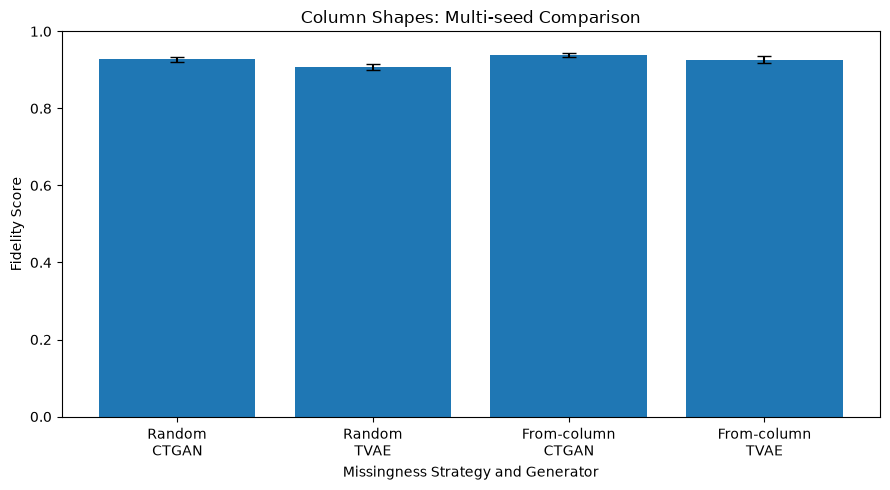

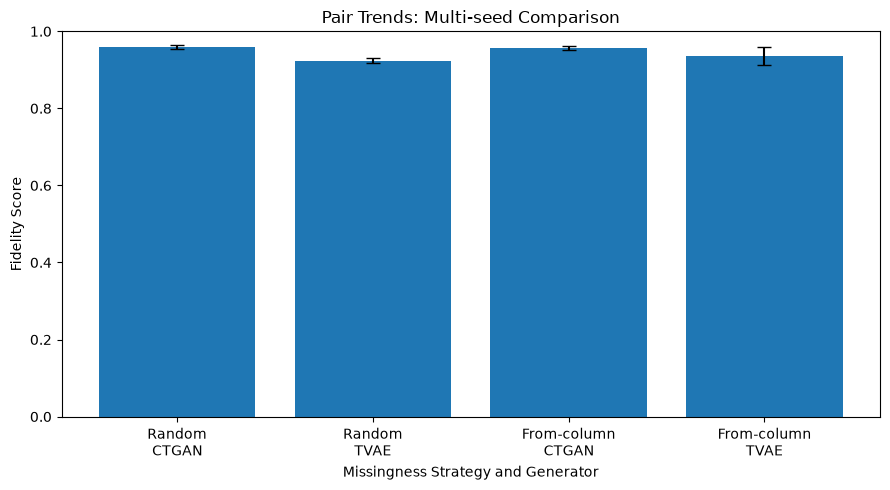

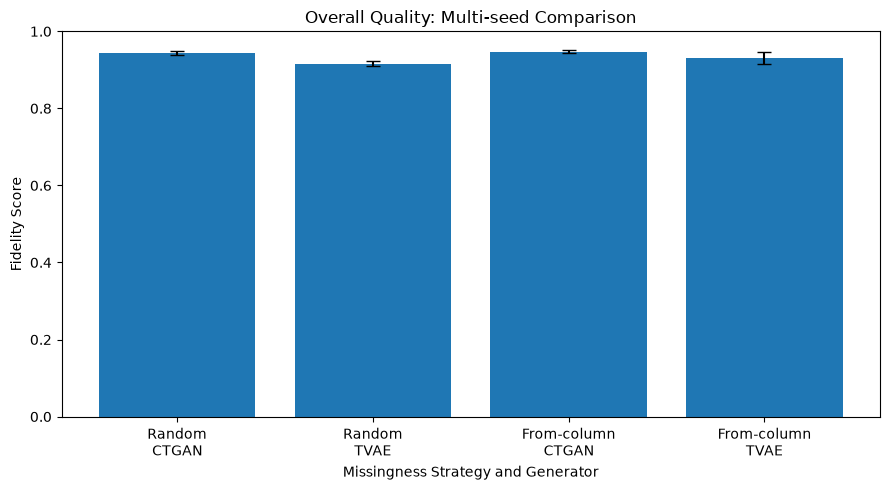

In [26]:

# ============================================================
# FIDELITY METRIC VISUALIZATIONS
# Mean ± Standard Deviation across four seeds
# ============================================================

metrics = {
    "column_shapes": "Column Shapes",
    "pair_trends": "Pair Trends",
    "overall_quality": "Overall Quality"
}

labels = [
    ("random", "ctgan"),
    ("random", "tvae"),
    ("from_column", "ctgan"),
    ("from_column", "tvae")
]

x_labels = [
    "Random\nCTGAN",
    "Random\nTVAE",
    "From-column\nCTGAN",
    "From-column\nTVAE"
]

for metric, title in metrics.items():

    means = [
        plot_means.loc[label, metric]
        for label in labels
    ]

    errors = [
        plot_stds.loc[label, metric]
        for label in labels
    ]

    plt.figure(figsize=(9, 5))

    plt.bar(
        x_labels,
        means,
        yerr=errors,
        capsize=5
    )

    plt.title(f"{title}: Multi-seed Comparison")
    plt.ylabel("Fidelity Score")
    plt.xlabel("Missingness Strategy and Generator")
    plt.ylim(0, 1)

    plt.tight_layout()
    plt.show()


Missingness similarity comparison

In [27]:

# ============================================================
# FEATURE-LEVEL MISSINGNESS ANALYSIS
# ============================================================

missingness_rows = []

for result_key, report in multi_seed_results.items():

    seed = report["seed"]
    strategy = report["strategy"]

    for generator, result in report["generators"].items():

        for feature, score in result[
            "missing_value_similarity"
        ].items():

            missingness_rows.append({

                "Seed": seed,

                "Strategy": strategy,

                "Generator": generator.upper(),

                "Feature": feature,

                "Missing Value Similarity": score,

                "Missing Rate Difference (pp)": (
                    result[
                        "missing_rate_difference_points"
                    ][feature]
                )
            })


missingness_df = pd.DataFrame(missingness_rows)

print("FEATURE-LEVEL MISSINGNESS RESULTS")

display(
    missingness_df.round(4)
)


# Aggregate feature-level results across seeds.

missingness_summary = (
    missingness_df
    .groupby(["Strategy", "Generator", "Feature"])[
        [
            "Missing Value Similarity",
            "Missing Rate Difference (pp)"
        ]
    ]
    .agg(["mean", "std"])
    .round(4)
)

print("\nMISSINGNESS: MEAN ± STANDARD DEVIATION")

display(missingness_summary)


FEATURE-LEVEL MISSINGNESS RESULTS


,Seed,Strategy,Generator,Feature,Missing Value Similarity,Missing Rate Difference (pp)
0,42,random,CTGAN,nevents,0.9996,0.04
1,42,random,CTGAN,ndays_act,0.9995,-0.05
2,42,random,CTGAN,ncontent,1.0000,0.00
3,42,random,CTGAN,nforum_posts,0.9962,0.38
4,42,random,TVAE,nevents,0.9996,0.04
...,...,...,...,...,...,...
59,3407,from_column,CTGAN,nforum_posts,0.9439,-5.61
60,3407,from_column,TVAE,nevents,0.9880,-1.20
61,3407,from_column,TVAE,ndays_act,0.9771,-2.29
62,3407,from_column,TVAE,ncontent,1.0000,0.00



MISSINGNESS: MEAN ± STANDARD DEVIATION


Missing Value Similarity          \
                                                       mean     std   
Strategy    Generator Feature                                         
from_column CTGAN     ncontent                       1.0000  0.0000   
                      ndays_act                      0.9639  0.0185   
                      nevents                        0.9560  0.0314   
                      nforum_posts                   0.9560  0.0193   
            TVAE      ncontent                       1.0000  0.0000   
                      ndays_act                      0.9204  0.0384   
                      nevents                        0.9707  0.0305   
                      nforum_posts                   0.9819  0.0146   
random      CTGAN     ncontent                       1.0000  0.0000   
                      ndays_act                      0.9995  0.0000   
                      nevents                        0.9996  0.0000   
                      nforum_posts                   0.9962  0.0000   
            TVAE      ncontent                       1.0000  0.0000   
                      ndays_act                      0.9995  0.0000   
                      nevents                        0.9996  0.0000   
                      nforum_posts                   0.9962  0.0000   

                                   Missing Rate Difference (pp)          
                                                           mean     std  
Strategy    Generator Feature                                            
from_column CTGAN     ncontent                           0.0000  0.0000  
                      ndays_act                         -0.6675  4.4994  
                      nevents                            0.8600  5.8914  
                      nforum_posts                       1.5975  5.1151  
            TVAE      ncontent                           0.0000  0.0000  
                      ndays_act                         -7.9575  3.8450  
                      nevents                           -2.9250  3.0443  
                      nforum_posts                      -1.1350  2.1934  
random      CTGAN     ncontent                           0.0000  0.0000  
                      ndays_act                         -0.0500  0.0000  
                      nevents                            0.0400  0.0000  
                      nforum_posts                       0.3800  0.0000  
            TVAE      ncontent                           0.0000  0.0000  
                      ndays_act                         -0.0500  0.0000  
                      nevents                            0.0400  0.0000  
                      nforum_posts                       0.3800  0.0000

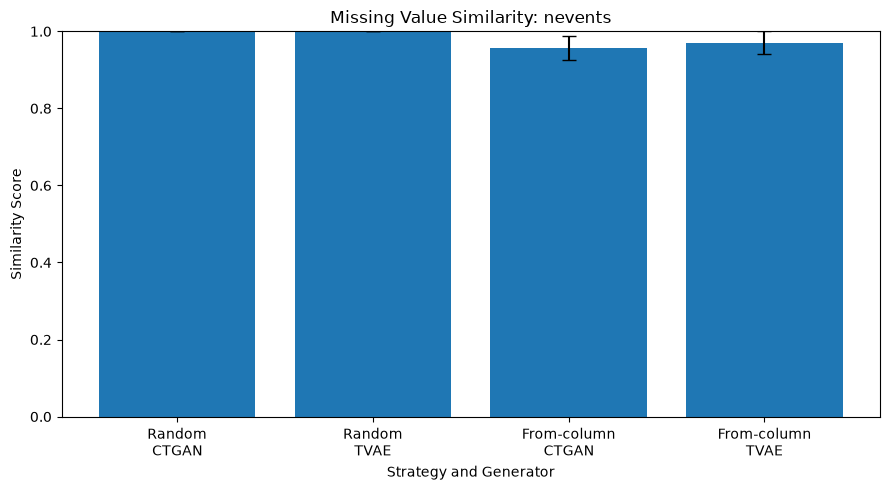

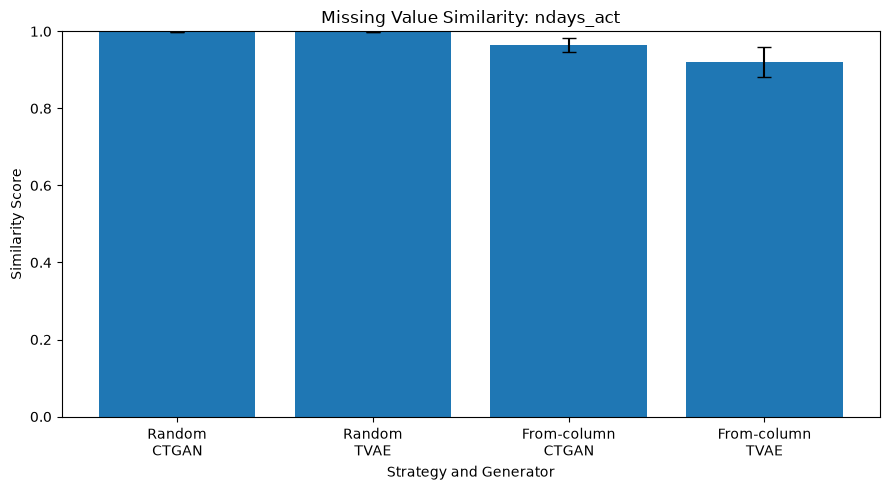

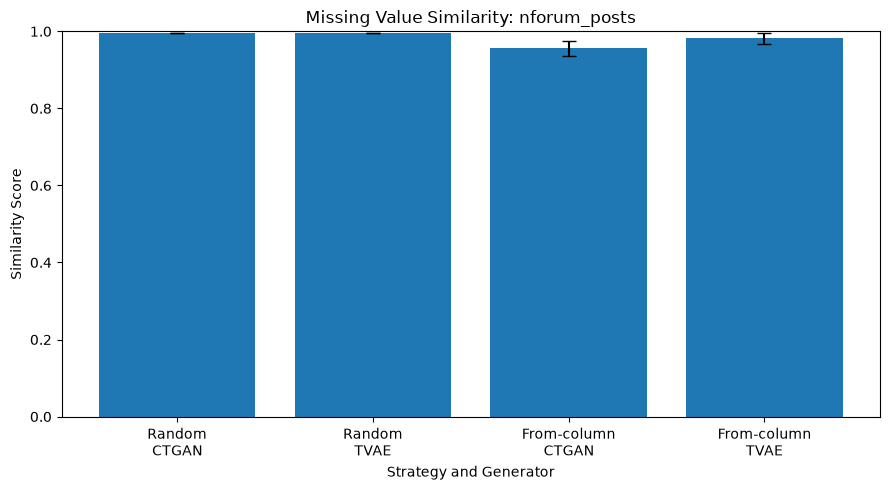

In [28]:

# ============================================================
# MISSINGNESS SIMILARITY BY FEATURE
# ============================================================

features_with_gaps = [
    "nevents",
    "ndays_act",
    "nforum_posts"
]

for feature in features_with_gaps:

    feature_data = missingness_df[
        missingness_df["Feature"] == feature
    ]

    grouped = (
        feature_data
        .groupby(["Strategy", "Generator"])[
            "Missing Value Similarity"
        ]
        .agg(["mean", "std"])
    )

    labels = [
        ("random", "CTGAN"),
        ("random", "TVAE"),
        ("from_column", "CTGAN"),
        ("from_column", "TVAE")
    ]

    x_labels = [
        "Random\nCTGAN",
        "Random\nTVAE",
        "From-column\nCTGAN",
        "From-column\nTVAE"
    ]

    means = [
        grouped.loc[label, "mean"]
        for label in labels
    ]

    errors = [
        grouped.loc[label, "std"]
        for label in labels
    ]

    plt.figure(figsize=(9, 5))

    plt.bar(
        x_labels,
        means,
        yerr=errors,
        capsize=5
    )

    plt.title(
        f"Missing Value Similarity: {feature}"
    )

    plt.ylabel("Similarity Score")
    plt.xlabel("Strategy and Generator")
    plt.ylim(0, 1)

    plt.tight_layout()
    plt.show()


Final interpretation

In [29]:
print("=" * 75)
print("FINAL MULTI-SEED FIDELITY EVALUATION")
print("=" * 75)

for (strategy, generator), row in plot_means.iterrows():

    overall_mean = row["overall_quality"]
    overall_std = plot_stds.loc[
        (strategy, generator),
        "overall_quality"
    ]

    print(
        f"{strategy} | {generator.upper()}: "
        f"Overall Quality = "
        f"{overall_mean:.4f} ± {overall_std:.4f}"
    )

print("\nInterpretation reminders:")
print("1. Column Shapes measures individual column distributions.")
print("2. Pair Trends measures relationships between feature pairs.")
print("3. Overall Quality is the mean of Column Shapes and Pair Trends.")
print("4. Missing Value Similarity measures missingness-pattern similarity.")
print("5. Random restoration uses fixed missingness rates.")
print("6. High statistical fidelity does not guarantee predictive utility.")
print("7. Standard deviation measures variability across four seeds.")
print("8. The no-target baseline is evaluated separately.")

FINAL MULTI-SEED FIDELITY EVALUATION
from_column | CTGAN: Overall Quality = 0.9476 ± 0.0047
from_column | TVAE: Overall Quality = 0.9315 ± 0.0154
random | CTGAN: Overall Quality = 0.9437 ± 0.0040
random | TVAE: Overall Quality = 0.9160 ± 0.0072

Interpretation reminders:
1. Column Shapes measures individual column distributions.
2. Pair Trends measures relationships between feature pairs.
3. Overall Quality is the mean of Column Shapes and Pair Trends.
4. Missing Value Similarity measures missingness-pattern similarity.
5. Random restoration uses fixed missingness rates.
6. High statistical fidelity does not guarantee predictive utility.
7. Standard deviation measures variability across four seeds.
8. The no-target baseline is evaluated separately.
